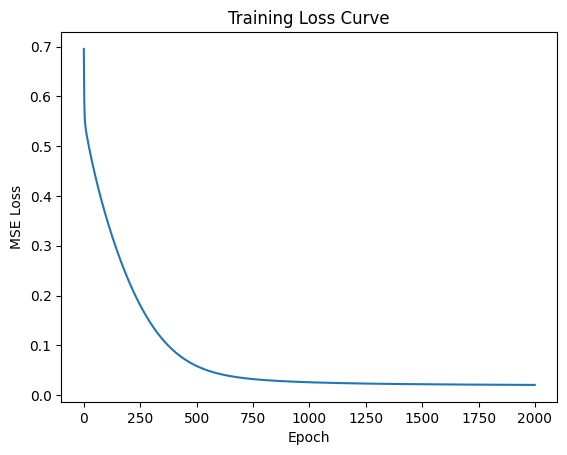

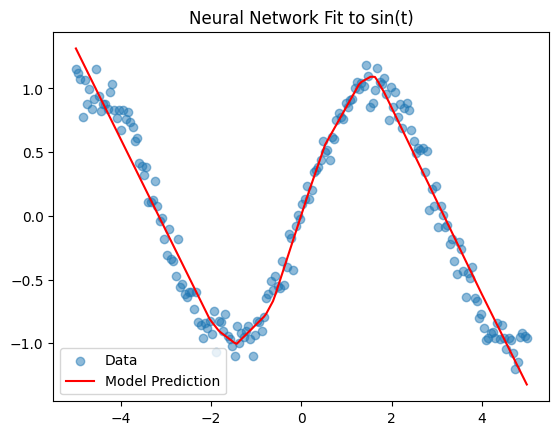

In [2]:
# Generated with chatGPT


import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# ----------------------
# Data generation
# ----------------------
def generate_data(n=200, T=5, sigma=0.1, seed=42):
    torch.manual_seed(seed)
    t = torch.linspace(-T, T, n).unsqueeze(1)  # shape (n,1)
    y = torch.sin(t) + sigma * torch.randn_like(t)
    return t, y

# ----------------------
# Model definition
# ----------------------
class SimpleNN(nn.Module):
    def __init__(self, d=16):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, d)   # input: t (1D) → hidden (dD)
        self.relu = nn.ReLU()
        self.output = nn.Linear(d, 1)   # hidden (dD) → output (1D)
        
    def forward(self, t):
        return self.output(self.relu(self.hidden(t)))

# ----------------------
# Training loop
# ----------------------
def train_model(d=16, lr=1e-2, n_epochs=2000):
    # Data
    t, y = generate_data()
    
    # Model
    model = SimpleNN(d=d)
    criterion = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    losses = []
    for epoch in range(n_epochs):
        optimizer.zero_grad()
        y_pred = model(t)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
    
    return model, t, y, losses

# ----------------------
# Run experiment
# ----------------------
if __name__ == "__main__":
    model, t, y, losses = train_model(d=16, lr=0.01)
    
    # Plot training loss
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Curve")
    plt.show()
    
    # Plot predictions vs true values
    with torch.no_grad():
        y_pred = model(t)
    plt.scatter(t.numpy(), y.numpy(), label="Data", alpha=0.5)
    plt.plot(t.numpy(), y_pred.numpy(), color="red", label="Model Prediction")
    plt.legend()
    plt.title("Neural Network Fit to sin(t)")
    plt.show()